In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("DailyDelhiClimateTrain.csv", parse_dates=["date"])

df = df.sort_values("date").reset_index(drop=True)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Dataset shape: (1462, 5)

Columns:
['date', 'meantemp', 'humidity', 'wind_speed', 'meanpressure']


,date,meantemp,humidity,wind_speed,meanpressure
0,2013-01-01,10.000000,84.500000,0.000000,1015.666667
1,2013-01-02,7.400000,92.000000,2.980000,1017.800000
2,2013-01-03,7.166667,87.000000,4.633333,1018.666667
3,2013-01-04,8.666667,71.333333,1.233333,1017.166667
4,2013-01-05,6.000000,86.833333,3.700000,1016.500000


In [2]:
print("Dataset Information:")
df.info()

print("\nMissing Values:")
print(df.isnull().sum())

print("\nDuplicate Rows:", df.duplicated().sum())

print("\nDate Range:")
print("Start Date:", df["date"].min())
print("End Date:", df["date"].max())

print("\nStatistical Summary:")
display(df.describe())

Dataset Information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1462 entries, 0 to 1461
Data columns (total 5 columns):
 #   Column        Non-Null Count  Dtype         
---  ------        --------------  -----         
 0   date          1462 non-null   datetime64[ns]
 1   meantemp      1462 non-null   float64       
 2   humidity      1462 non-null   float64       
 3   wind_speed    1462 non-null   float64       
 4   meanpressure  1462 non-null   float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 57.2 KB

Missing Values:
date            0
meantemp        0
humidity        0
wind_speed      0
meanpressure    0
dtype: int64

Duplicate Rows: 0

Date Range:
Start Date: 2013-01-01 00:00:00
End Date: 2017-01-01 00:00:00

Statistical Summary:


,date,meantemp,humidity,wind_speed,meanpressure
count,1462,1462.000000,1462.000000,1462.000000,1462.000000
mean,2015-01-01 12:00:00,25.495521,60.771702,6.802209,1011.104548
min,2013-01-01 00:00:00,6.000000,13.428571,0.000000,-3.041667
25%,2014-01-01 06:00:00,18.857143,50.375000,3.475000,1001.580357
50%,2015-01-01 12:00:00,27.714286,62.625000,6.221667,1008.563492
75%,2016-01-01 18:00:00,31.305804,72.218750,9.238235,1014.944901
max,2017-01-01 00:00:00,38.714286,100.000000,42.220000,7679.333333
std,NaN,7.348103,16.769652,4.561602,180.231668


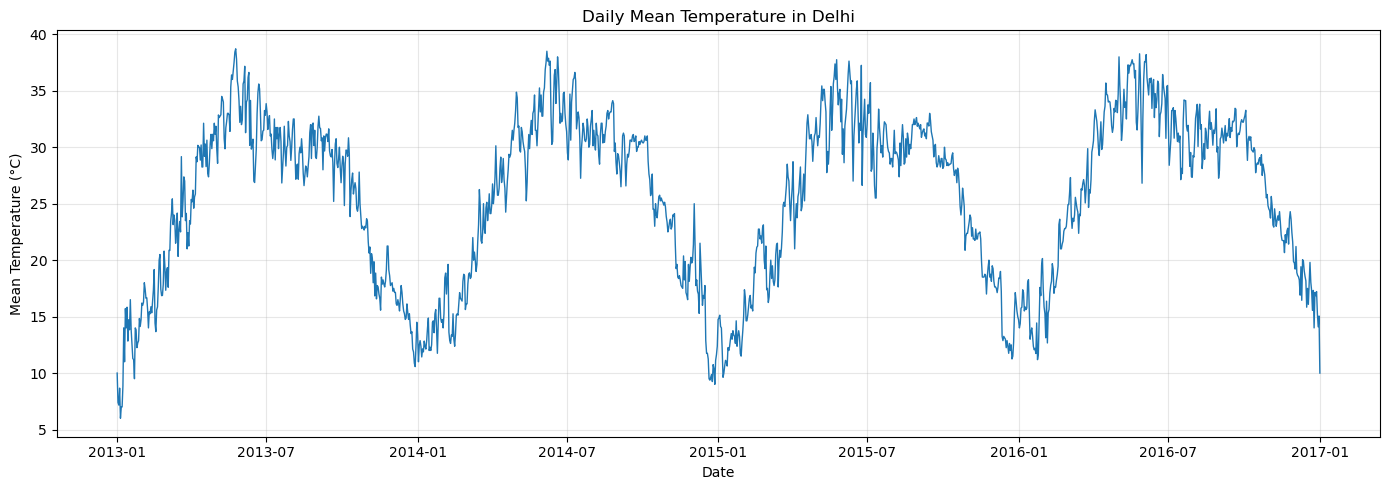

In [3]:
plt.figure(figsize=(14, 5))

plt.plot(df["date"], df["meantemp"], linewidth=1)

plt.title("Daily Mean Temperature in Delhi")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [4]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.dummy import DummyRegressor
import numpy as np
import pandas as pd

df["date"] = pd.to_datetime(df["date"])
df = df.sort_values("date").reset_index(drop=True)

series = df[["date", "meantemp"]].dropna().copy()

split_index = int(len(series) * 0.8)

train = series.iloc[:split_index].copy()
test = series.iloc[split_index:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))
print("Training ends:", train["date"].max())
print("Testing starts:", test["date"].min())

Training observations: 1169
Testing observations: 293
Training ends: 2016-03-14 00:00:00
Testing starts: 2016-03-15 00:00:00


In [5]:
last_temperature = train["meantemp"].iloc[-1]

y_true = test["meantemp"].to_numpy()
y_pred_baseline = np.full(len(test), last_temperature)

mae_baseline = mean_absolute_error(y_true, y_pred_baseline)
rmse_baseline = np.sqrt(mean_squared_error(y_true, y_pred_baseline))

print("Baseline MAE:", round(mae_baseline, 3))
print("Baseline RMSE:", round(rmse_baseline, 3))

Baseline MAE: 8.001
Baseline RMSE: 8.892


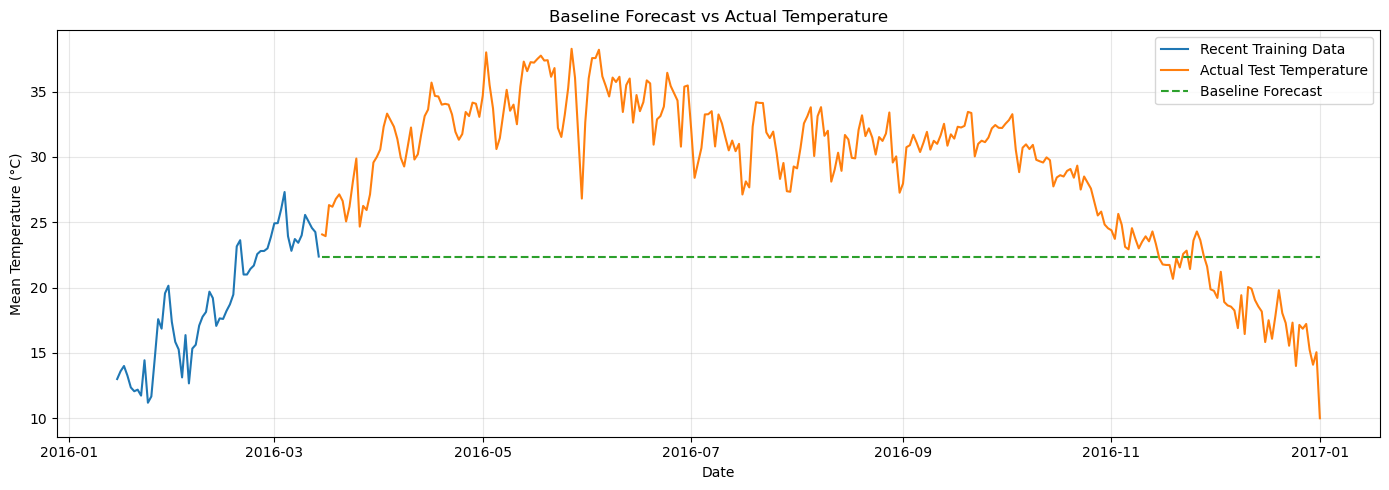

In [6]:
plt.figure(figsize=(14, 5))

plt.plot(
    train["date"].tail(60),
    train["meantemp"].tail(60),
    label="Recent Training Data"
)

plt.plot(
    test["date"],
    y_true,
    label="Actual Test Temperature"
)

plt.plot(
    test["date"],
    y_pred_baseline,
    label="Baseline Forecast",
    linestyle="--"
)

plt.title("Baseline Forecast vs Actual Temperature")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [8]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

seasonal_period = 365

train_values = train["meantemp"].to_numpy()
test_values = test["meantemp"].to_numpy()

seasonal_predictions = []

for i in range(len(test_values)):
    source_index = len(train_values) + i - seasonal_period

    if source_index < 0:
        seasonal_predictions.append(train_values[-1])
    else:
        seasonal_predictions.append(
            np.concatenate([train_values, test_values[:i]])[source_index]
        )

seasonal_predictions = np.array(seasonal_predictions)

mae_seasonal = mean_absolute_error(test_values, seasonal_predictions)
rmse_seasonal = np.sqrt(
    mean_squared_error(test_values, seasonal_predictions)
)

print("Seasonal Naive MAE:", round(mae_seasonal, 3))
print("Seasonal Naive RMSE:", round(rmse_seasonal, 3))

Seasonal Naive MAE: 2.777
Seasonal Naive RMSE: 3.532


In [9]:
comparison = pd.DataFrame({
    "Model": ["Last Value Baseline", "Seasonal Naive (365 days)"],
    "MAE": [mae_baseline, mae_seasonal],
    "RMSE": [rmse_baseline, rmse_seasonal]
})

display(comparison.round(3))

,Model,MAE,RMSE
0,Last Value Baseline,8.001,8.892
1,Seasonal Naive (365 days),2.777,3.532


In [10]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error

values = train["meantemp"].to_numpy()

validation_size = int(len(values) * 0.2)

fit_values = values[:-validation_size]
validation_actual = values[-validation_size:]

# Baseline forecast: last observed value
validation_pred = np.full(
    len(validation_actual),
    fit_values[-1]
)

validation_errors = validation_actual - validation_pred

print("Validation observations:", len(validation_actual))
print("Validation MAE:", round(
    mean_absolute_error(validation_actual, validation_pred), 3
))
print("Validation error standard deviation:", round(
    np.std(validation_errors, ddof=1), 3
))

Validation observations: 233
Validation MAE: 8.249
Validation error standard deviation: 6.488


In [11]:
error_quantile = np.quantile(
    np.abs(validation_errors),
    0.90
)

print("90% interval half-width:", round(error_quantile, 3))

90% interval half-width: 17.604


In [12]:
forecast_results = pd.DataFrame({
    "Date": test["date"].to_numpy(),
    "Actual": test["meantemp"].to_numpy(),
    "Forecast": y_pred_baseline
})

forecast_results["Lower_90"] = (
    forecast_results["Forecast"] - error_quantile
)

forecast_results["Upper_90"] = (
    forecast_results["Forecast"] + error_quantile
)

display(forecast_results.head())

,Date,Actual,Forecast,Lower_90,Upper_90
0,2016-03-15,24.066667,22.375,4.77119,39.97881
1,2016-03-16,23.937500,22.375,4.77119,39.97881
2,2016-03-17,26.312500,22.375,4.77119,39.97881
3,2016-03-18,26.187500,22.375,4.77119,39.97881
4,2016-03-19,26.785714,22.375,4.77119,39.97881


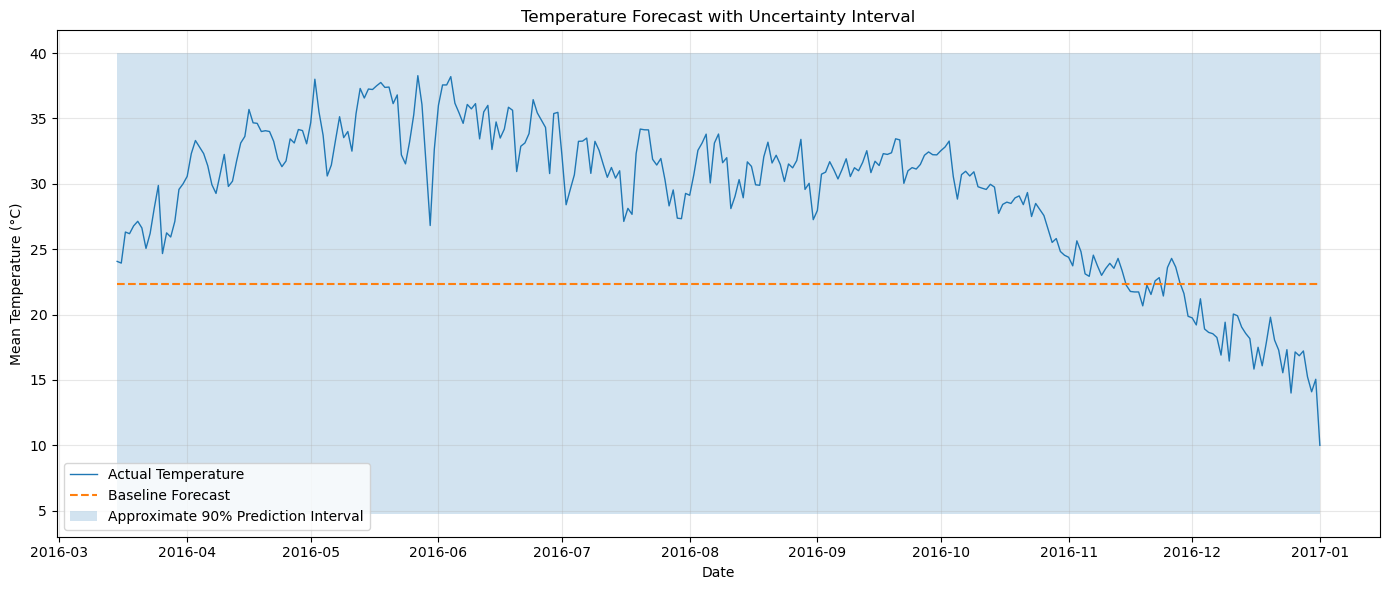

In [13]:
plt.figure(figsize=(14, 6))

plt.plot(
    forecast_results["Date"],
    forecast_results["Actual"],
    label="Actual Temperature",
    linewidth=1
)

plt.plot(
    forecast_results["Date"],
    forecast_results["Forecast"],
    label="Baseline Forecast",
    linestyle="--"
)

plt.fill_between(
    forecast_results["Date"],
    forecast_results["Lower_90"],
    forecast_results["Upper_90"],
    alpha=0.2,
    label="Approximate 90% Prediction Interval"
)

plt.title("Temperature Forecast with Uncertainty Interval")
plt.xlabel("Date")
plt.ylabel("Mean Temperature (°C)")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [14]:
inside_interval = (
    (forecast_results["Actual"] >= forecast_results["Lower_90"]) &
    (forecast_results["Actual"] <= forecast_results["Upper_90"])
)

coverage = inside_interval.mean() * 100

print("Target Coverage: 90%")
print("Actual Test Coverage:", round(coverage, 2), "%")

print(
    "Observations inside interval:",
    inside_interval.sum(),
    "out of",
    len(inside_interval)
)

Target Coverage: 90%
Actual Test Coverage: 100.0 %
Observations inside interval: 293 out of 293


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

actual = forecast_results["Actual"]
predicted = forecast_results["Forecast"]

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("Final Test MAE:", round(mae, 3), "°C")
print("Final Test RMSE:", round(rmse, 3), "°C")
print("Actual 90% Interval Coverage:", round(coverage, 2), "%")

Final Test MAE: 8.001 °C
Final Test RMSE: 8.892 °C
Actual 90% Interval Coverage: 100.0 %


In [16]:
forecast_results.to_csv(
    "temperature_forecast_with_intervals.csv",
    index=False
)

comparison.to_csv(
    "model_comparison.csv",
    index=False
)

print("Forecast results saved successfully!")

Forecast results saved successfully!


In [17]:
forecast_results["Interval_Width"] = (
    forecast_results["Upper_90"] -
    forecast_results["Lower_90"]
)

print(
    "Average Interval Width:",
    round(forecast_results["Interval_Width"].mean(), 3),
    "°C"
)

print(
    "Minimum Interval Width:",
    round(forecast_results["Interval_Width"].min(), 3),
    "°C"
)

print(
    "Maximum Interval Width:",
    round(forecast_results["Interval_Width"].max(), 3),
    "°C"
)

Average Interval Width: 35.208 °C
Minimum Interval Width: 35.208 °C
Maximum Interval Width: 35.208 °C


In [18]:
summary = pd.DataFrame({
    "Metric": [
        "Test MAE",
        "Test RMSE",
        "Target Coverage",
        "Actual Coverage",
        "Average Interval Width"
    ],
    "Value": [
        mae,
        rmse,
        90.0,
        coverage,
        forecast_results["Interval_Width"].mean()
    ]
})

display(summary.round(3))

summary.to_csv("forecast_evaluation_summary.csv", index=False)

print("Evaluation summary saved successfully!")

,Metric,Value
0,Test MAE,8.001
1,Test RMSE,8.892
2,Target Coverage,90.000
3,Actual Coverage,100.000
4,Average Interval Width,35.208


Evaluation summary saved successfully!
